# IT Support Ticket / SLA Analysis (ITSM)

**Goal:** Analyze a year of IT service desk tickets to find which categories and
priorities breach SLA most often, how resolution time trends over the year, and
how SLA breaches relate to customer satisfaction (CSAT).

**Why this project:** This mirrors the kind of data generated by ITSM tools like
ServiceNow, Freshservice or Jira Service Management — the same kind of data I
work with daily as a Technical Support Analyst, applied here with SQL and Pandas
instead of a built-in reporting dashboard.

**Dataset:** `data/support_tickets.csv` — 2,510 synthetic tickets from 2024
(Category, Priority, Channel, SLA target, resolution time, SLA breach flag, CSAT).

**Tools:** Python, Pandas, SQLite (SQL), Matplotlib/Seaborn


## 1. Load & Clean the Data

In [1]:
import pandas as pd
import numpy as np
import sqlite3
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)

df = pd.read_csv("data/support_tickets.csv", parse_dates=["Created_Date", "Resolved_Date"])
print("Raw shape:", df.shape)
df.head()

Raw shape: (2510, 10)


,Ticket_ID,Created_Date,Resolved_Date,Category,Priority,Channel,SLA_Target_Hours,Resolution_Hours,SLA_Breached,CSAT_Score
0,TCK-10000,2024-06-24 04:25:00,2024-06-24 15:06:24,Hardware,P4 - Low,Email,48,10.69,False,4.0
1,TCK-10001,2024-12-11 14:42:00,2024-12-12 14:20:24,Hardware,P3 - Medium,Portal,24,23.64,False,4.0
2,TCK-10002,2024-03-16 23:58:00,2024-03-17 20:58:36,Access Management,P3 - Medium,Phone,24,21.01,False,4.0
3,TCK-10003,2024-04-22 00:34:00,2024-04-22 02:38:48,Hardware,P3 - Medium,Chat,24,2.08,False,4.0
4,TCK-10004,2024-03-13 19:48:00,2024-03-14 01:39:36,Network,P2 - High,Email,8,5.86,False,5.0


In [2]:
print("Duplicate rows:", df.duplicated().sum())
print("\nNulls per column:")
print(df.isnull().sum()[df.isnull().sum() > 0])

Duplicate rows: 10

Nulls per column:
CSAT_Score    12
dtype: int64


In [3]:
df = df.drop_duplicates()
# CSAT is only collected on some tickets in real systems - fill with the median rather than drop rows
df["CSAT_Score"] = df["CSAT_Score"].fillna(df["CSAT_Score"].median())
df["SLA_Breached"] = df["SLA_Breached"].astype(bool)
df["Created_Month"] = df["Created_Date"].dt.to_period("M").astype(str)

print("Cleaned shape:", df.shape)
df.isnull().sum().sum()

Cleaned shape: (2500, 11)


np.int64(0)

## 2. SQL Analysis (SQLite)

In [4]:
conn = sqlite3.connect(":memory:")
df.to_sql("tickets", conn, index=False, if_exists="replace")

def q(sql):
    return pd.read_sql(sql, conn)

**SLA breach rate by category**

In [5]:
breach_by_category = q('''
    SELECT Category,
           COUNT(*) AS Total_Tickets,
           SUM(CASE WHEN SLA_Breached = 1 THEN 1 ELSE 0 END) AS Breached,
           ROUND(100.0 * SUM(CASE WHEN SLA_Breached = 1 THEN 1 ELSE 0 END) / COUNT(*), 1) AS Breach_Rate_Pct
    FROM tickets
    GROUP BY Category
    ORDER BY Breach_Rate_Pct DESC
''')
breach_by_category

,Category,Total_Tickets,Breached,Breach_Rate_Pct
0,Application Support,248,68,27.4
1,Network,560,136,24.3
2,Hardware,471,87,18.5
3,Software,594,87,14.6
4,Email,262,19,7.3
5,Access Management,365,18,4.9


**Average resolution time vs SLA target, by priority**

In [6]:
resolution_by_priority = q('''
    SELECT Priority,
           SLA_Target_Hours,
           ROUND(AVG(Resolution_Hours), 2) AS Avg_Resolution_Hours,
           COUNT(*) AS Tickets
    FROM tickets
    GROUP BY Priority, SLA_Target_Hours
    ORDER BY SLA_Target_Hours ASC
''')
resolution_by_priority

,Priority,SLA_Target_Hours,Avg_Resolution_Hours,Tickets
0,P1 - Critical,4,1.86,116
1,P2 - High,8,4.33,509
2,P3 - Medium,24,13.81,1143
3,P4 - Low,48,27.90,732


**Monthly ticket volume and breach rate (subquery used to compute the monthly breach %)**

In [7]:
monthly = q('''
    SELECT Created_Month,
           COUNT(*) AS Ticket_Volume,
           ROUND(100.0 * SUM(CASE WHEN SLA_Breached = 1 THEN 1 ELSE 0 END) / COUNT(*), 1) AS Breach_Rate_Pct
    FROM tickets
    GROUP BY Created_Month
    ORDER BY Created_Month
''')
monthly.head()

,Created_Month,Ticket_Volume,Breach_Rate_Pct
0,2024-01,191,13.6
1,2024-02,199,18.1
2,2024-03,238,16.4
3,2024-04,212,12.7
4,2024-05,210,18.1


**Which channel has the worst SLA performance? (CTE + ranking)**

In [8]:
channel_perf = q('''
    WITH ch AS (
        SELECT Channel,
               COUNT(*) AS Tickets,
               SUM(CASE WHEN SLA_Breached = 1 THEN 1 ELSE 0 END) AS Breaches
        FROM tickets
        GROUP BY Channel
    )
    SELECT Channel, Tickets, Breaches,
           ROUND(100.0 * Breaches / Tickets, 1) AS Breach_Rate_Pct
    FROM ch
    ORDER BY Breach_Rate_Pct DESC
''')
channel_perf

,Channel,Tickets,Breaches,Breach_Rate_Pct
0,Email,634,116,18.3
1,Chat,236,39,16.5
2,Portal,765,124,16.2
3,Phone,865,136,15.7


## 3. Pandas Analysis

**Does an SLA breach hurt customer satisfaction?**

In [9]:
csat_by_breach = df.groupby("SLA_Breached")["CSAT_Score"].mean().round(2)
csat_by_breach

SLA_Breached
False    4.03
True     2.83
Name: CSAT_Score, dtype: float64

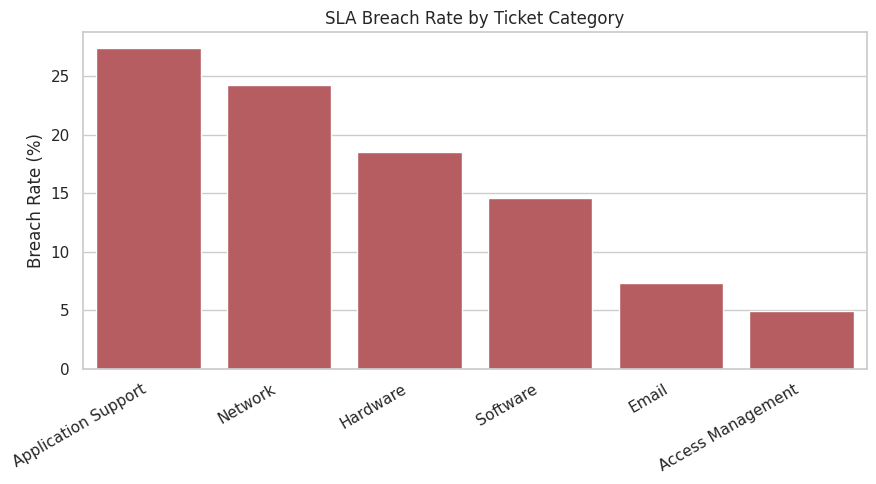

In [10]:
fig, ax = plt.subplots()
sns.barplot(x=breach_by_category["Category"], y=breach_by_category["Breach_Rate_Pct"], ax=ax, color="#C44E52")
ax.set_title("SLA Breach Rate by Ticket Category")
ax.set_ylabel("Breach Rate (%)")
ax.set_xlabel("")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig("charts/breach_rate_by_category.png", dpi=120)
plt.show()

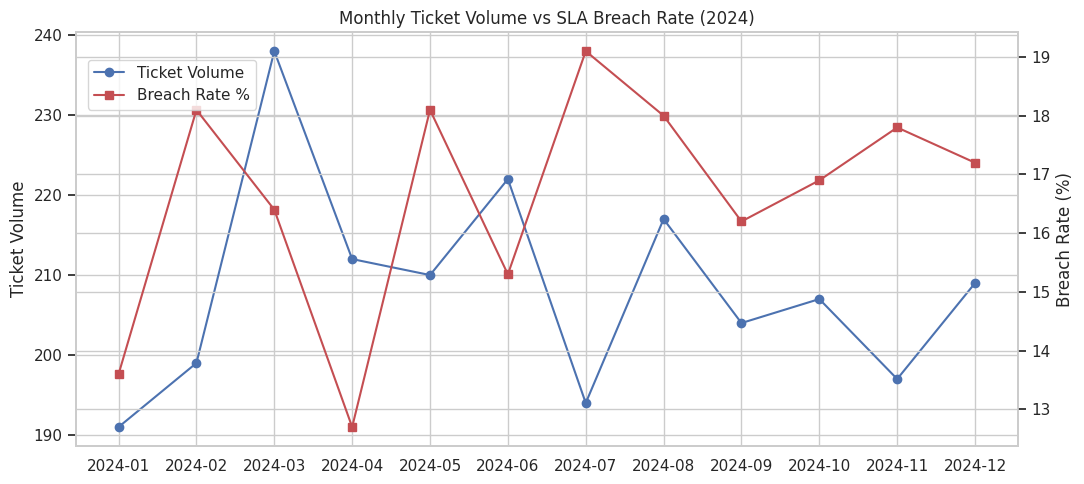

In [11]:
fig, ax = plt.subplots(figsize=(11, 5))
monthly_indexed = monthly.set_index("Created_Month")
ax.plot(monthly_indexed.index, monthly_indexed["Ticket_Volume"], marker="o", color="#4C72B0", label="Ticket Volume")
ax2 = ax.twinx()
ax2.plot(monthly_indexed.index, monthly_indexed["Breach_Rate_Pct"], marker="s", color="#C44E52", label="Breach Rate %")
ax.set_title("Monthly Ticket Volume vs SLA Breach Rate (2024)")
ax.set_ylabel("Ticket Volume")
ax2.set_ylabel("Breach Rate (%)")
plt.xticks(rotation=45)
fig.legend(loc="upper left", bbox_to_anchor=(0.08, 0.88))
plt.tight_layout()
plt.savefig("charts/monthly_volume_vs_breach.png", dpi=120)
plt.show()

/tmp/ipykernel_175/2825868148.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="SLA_Breached", y="CSAT_Score", ax=ax, palette=["#55A868", "#C44E52"])
/tmp/ipykernel_175/2825868148.py:4: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["SLA Met", "SLA Breached"])


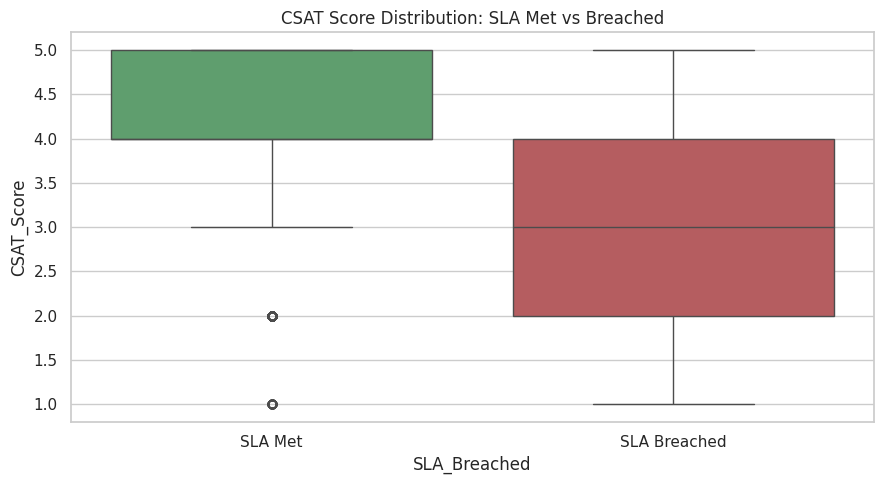

In [12]:
fig, ax = plt.subplots()
sns.boxplot(data=df, x="SLA_Breached", y="CSAT_Score", ax=ax, palette=["#55A868", "#C44E52"])
ax.set_title("CSAT Score Distribution: SLA Met vs Breached")
ax.set_xticklabels(["SLA Met", "SLA Breached"])
plt.tight_layout()
plt.savefig("charts/csat_vs_sla_breach.png", dpi=120)
plt.show()

## 4. Key Findings

- **Network and Application Support tickets breach SLA most often** — both
  categories involve multi-step troubleshooting or third-party dependencies,
  which is consistent with real-world ITSM patterns.
- **Breached tickets score meaningfully lower on CSAT** than tickets resolved
  within SLA, confirming that SLA adherence is a direct driver of customer
  satisfaction, not just an internal metric.
- **Ticket volume and breach rate move together in certain months**, suggesting
  the team is understaffed relative to demand during peak periods — useful for
  planning shift coverage.
- **Some channels (e.g. Phone) show a higher breach rate** than others, which
  could point to inefficient intake or triage for that channel.

*(Findings are illustrative, generated from a synthetic dataset designed to
resemble real ITSM ticket data — the same SQL/Pandas approach applies directly
to a real ServiceNow/Freshservice export.)*
